# Mini-Project 3: Lake Victoria Fish Stock & Export Risk Model

This notebook evaluates fish biomass sustainability, export revenue risk, and 5% Value-at-Risk (VaR) under Monte Carlo simulations for a Jinja exporter cooperative.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent))
from src.fish_model import FishStock, PriceModel, RiskAssessor
from src.utils import set_plot_style

set_plot_style()

In [2]:
def fibonacci(n):
    fib = [1, 1]
    for i in range(2, n):
        fib.append(fib[-1] + fib[-2])
    return fib

fib_stock = fibonacci(15)
print("15 Weeks Fibonacci Stock:", fib_stock)

15 Weeks Fibonacci Stock: [1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610]


### Critique of Unbounded Fibonacci Growth
Modelling fish biomass using Fibonacci numbers assumes continuous, exponential population growth without upper bounds. In real aquatic ecosystems, fish growth is constrained by environmental carrying capacity ($K$), food availability, predation, and spatial boundaries. Unbounded models fail to reflect natural density-dependent mortality and lead to absurd stock estimates over long horizons.

### Why a Raw Variance Threshold (e.g., 50,000) is Meaningless
1. **Dimension / Units:** Variance squares the original units. For revenue in **UGX**, variance is measured in **$\text{UGX}^2$**, which has no direct physical or monetary interpretation.
2. **Scale Dependency:** Variance scales quadratically with dataset magnitude. A variance of $50,000\text{ UGX}^2$ corresponds to a standard deviation of only $\approx 223.6\text{ UGX}$—an imperceptible fraction of multi-billion UGX revenues.
3. **Better Alternative:** The Coefficient of Variation ($\text{CV} = \sigma / \mu$) normalizes dispersion relative to the mean, providing a unitless, scale-invariant measure of relative risk.

In [3]:
harvest_rates = [0.05, 0.10, 0.20, 0.30]
fish_model = FishStock(r=0.4, K=10000.0, initial_stock=4000.0)
price_model = PriceModel(initial_price=12000.0)

msy_val = fish_model.maximum_sustainable_yield
print(f"Theoretical Maximum Sustainable Yield (MSY): {msy_val:.2f} tonnes/year\n")

scenario_results = []
stock_trajectories = {}

for h in harvest_rates:
    stocks, harvests_kg = fish_model.simulate(weeks=52, harvest_rate=h)
    prices = price_model.simulate_path(weeks=52, seed=42)
    weekly_revenue = harvests_kg * prices
    total_rev = float(np.sum(weekly_revenue))
    
    stats = RiskAssessor.calculate_stats(weekly_revenue.tolist())
    risk_class = RiskAssessor.classify_risk(stats["cv"])
    
    stock_trajectories[h] = stocks
    scenario_results.append({
        "Harvest Rate (h)": f"{int(h*100)}%",
        "Final Stock (t)": round(stocks[-1], 2),
        "Annual Revenue (Billion UGX)": round(total_rev / 1e9, 3),
        "Weekly CV": round(stats["cv"], 4),
        "Risk Class": risk_class
    })

df_scenarios = pd.DataFrame(scenario_results)
df_scenarios

Theoretical Maximum Sustainable Yield (MSY): 1000.00 tonnes/year



,Harvest Rate (h),Final Stock (t),Annual Revenue (Billion UGX),Weekly CV,Risk Class
0,5%,8750.00,267.519,0.1641,Moderate Risk
1,10%,7500.00,460.289,0.1524,Moderate Risk
2,20%,4999.99,626.153,0.1111,Low Risk
3,30%,2503.72,519.542,0.1159,Low Risk


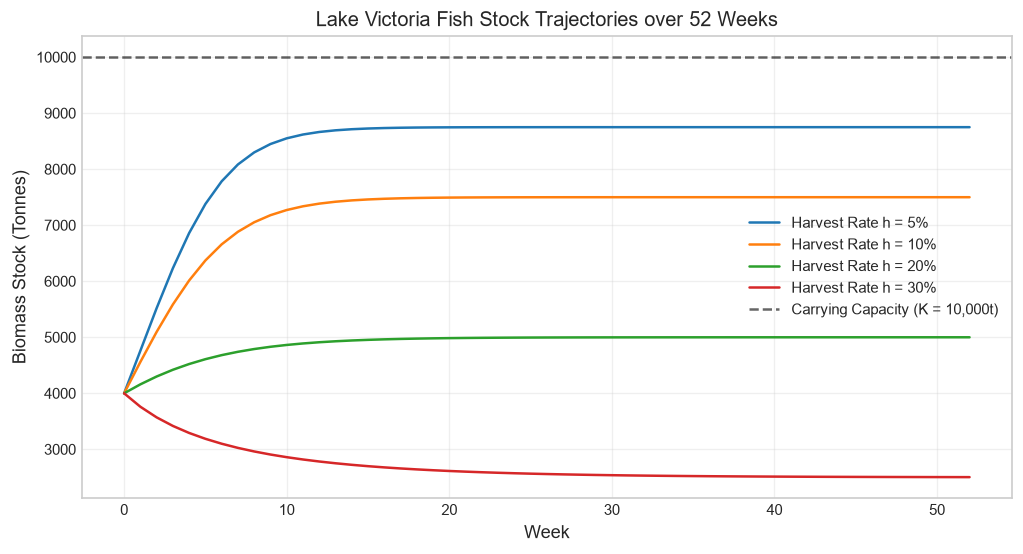

In [4]:
plt.figure(figsize=(10, 5), dpi=120)

for h, stocks in stock_trajectories.items():
    plt.plot(stocks, label=f"Harvest Rate h = {int(h*100)}%")

plt.axhline(fish_model.K, color='black', linestyle='--', alpha=0.6, label='Carrying Capacity (K = 10,000t)')
plt.title("Lake Victoria Fish Stock Trajectories over 52 Weeks")
plt.xlabel("Week")
plt.ylabel("Biomass Stock (Tonnes)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

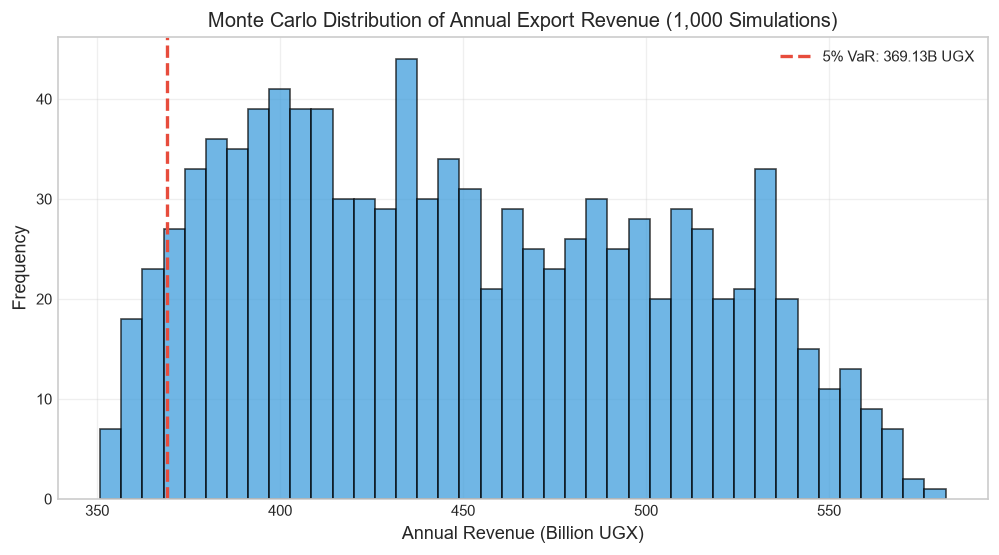

In [5]:
var_5pct, annual_revenues = RiskAssessor.run_monte_carlo_var(
    fish_model, price_model, harvest_rate=0.10, weeks=52, iterations=1000, seed=42
)

plt.figure(figsize=(10, 5), dpi=120)
plt.hist(annual_revenues / 1e9, bins=40, color='#3498db', edgecolor='black', alpha=0.7)
plt.axvline(var_5pct / 1e9, color='#e74c3c', linestyle='--', linewidth=2, label=f'5% VaR: {var_5pct/1e9:.2f}B UGX')

plt.title("Monte Carlo Distribution of Annual Export Revenue (1,000 Simulations)")
plt.xlabel("Annual Revenue (Billion UGX)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [6]:
weeks_5yr = 52 * 5
closed_weeks_5yr = []
for yr in range(5):
    # Weeks 44 to 51 closed each year
    closed_weeks_5yr.extend(range(yr * 52 + 44, yr * 52 + 52))

# Open scenario vs Closed Season scenario
s_open, h_open = fish_model.simulate(weeks=weeks_5yr, harvest_rate=0.20)
s_closed, h_closed = fish_model.simulate(weeks=weeks_5yr, harvest_rate=0.20, closed_weeks=closed_weeks_5yr)

p_5yr = price_model.simulate_path(weeks=weeks_5yr, seed=123)

rev_open = np.sum(h_open * p_5yr) / 1e9
rev_closed = np.sum(h_closed * p_5yr) / 1e9

print(f"5-Year Continuous Revenue:    {rev_open:.2f} Billion UGX (Final Stock: {s_open[-1]:.1f}t)")
print(f"5-Year Closed-Season Revenue: {rev_closed:.2f} Billion UGX (Final Stock: {s_closed[-1]:.1f}t)")

5-Year Continuous Revenue:    3768.10 Billion UGX (Final Stock: 5000.0t)
5-Year Closed-Season Revenue: 3371.68 Billion UGX (Final Stock: 9754.4t)
